<a href="https://colab.research.google.com/github/yulunwu000/artemis-lunar-plasma/blob/main/PAD_plots.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q pyspedas

#PAD plots for sawyer 2023, 2013 04 and 2014 04

peib: 153 spins in ['2013-12-04/00:05:20', '2013-12-04/00:16:10']
ion beam direction x = -0.97  ->  look_dir = False
peeb: 153 spins in ['2013-12-04/00:05:20', '2013-12-04/00:16:10']


28-Nov-26 15:03:49: /usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2197: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  return self._math_expression.parseString(toks[0][1:-1], parseAll=True)

28-Nov-26 15:03:59: /usr/local/lib/python3.13/dist-packages/pyparsing/util.py:466: PyparsingDeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)

28-Nov-26 15:03:39: /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)

28-Nov-26 15:03:39: /usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2170: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)

28-Nov-26 1

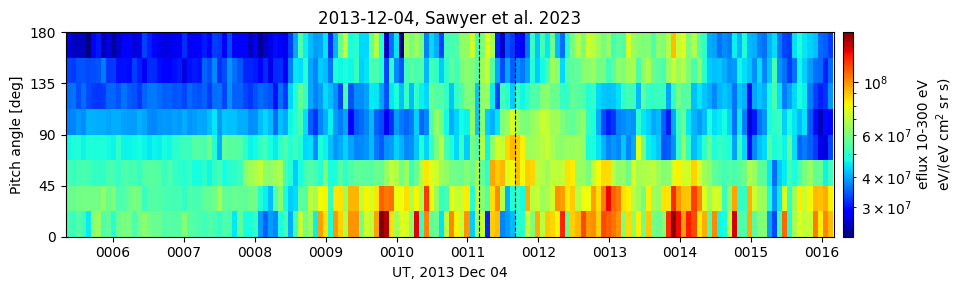

28-Nov-26 15:04:11: /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



peef: 145 spins in ['2013-01-14/23:57:00', '2013-01-15/00:07:00']


28-Nov-26 15:04:11: /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)

28-Nov-26 15:04:11: /usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2170: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)

28-Nov-26 15:04:21: /usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2197: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  return self._math_expression.parseString(toks[0][1:-1], parseAll=True)

28-Nov-26 15:04:21: /usr/local/lib/python3.13/dist-packages/pyparsing/util.py:466: PyparsingDeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)

28-Nov-26 1

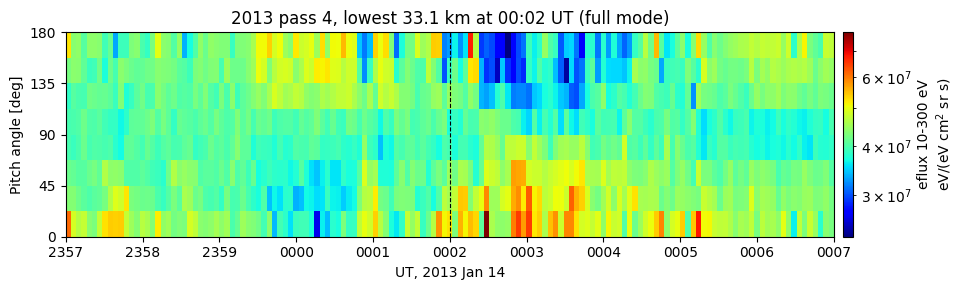

28-Nov-26 15:04:23: /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



peef: 127 spins in ['2014-05-26/20:31:00', '2014-05-26/20:40:00']


28-Nov-26 15:04:33: /usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2197: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  return self._math_expression.parseString(toks[0][1:-1], parseAll=True)

28-Nov-26 15:04:43: /usr/local/lib/python3.13/dist-packages/pyparsing/util.py:466: PyparsingDeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)

28-Nov-26 15:04:23: /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)

28-Nov-26 15:04:23: /usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2170: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)

28-Nov-26 1

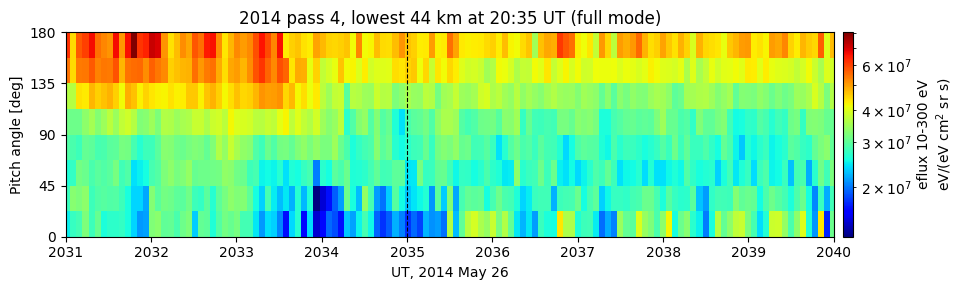

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LogNorm
import cdflib
from pyspedas import get_data, time_double
from pyspedas.projects import themis


import logging
import warnings

warnings.filterwarnings('ignore')
logging.getLogger().setLevel(logging.WARNING)

emin, emax = 10, 300     #maybe same as paper? maybe 10, 1000? not specified in paper really
pa_step = 22.5             # width of the pitch angle bins that matches the instruments resolution, any smaller and youre making up data points kinda

#reads 3D electron distribution
def read_dist(datatype, trange):
    # one file per day, so a pass that crosses midnight needs two files
    paths = themis.esd(trange=trange, probe='b', datatype=datatype, downloadonly=True)
    if not paths:
        print(f'{datatype}: no file for {trange}')
        return None

    parts = []
    for path in paths:
        cdf = cdflib.CDF(path)

        t0 = np.array(cdf.varget('time'), dtype=float)       # start of each spin (unix s)
        t1 = np.array(cdf.varget('end_time'), dtype=float)   # end of each spin
        flux = np.array(cdf.varget('eflux'), dtype=float)    # (time, 32 energies, 88 angles)
        good = np.array(cdf.varget('bins')) > 0               # which bins actually have data
        en_ind = np.array(cdf.varget('en_ind')).astype(int)
        an_ind = np.array(cdf.varget('an_ind')).astype(int)
        dphi = np.array(cdf.varget('phi_offset'), dtype=float) + np.array(cdf.varget('eclipse_dphi'), dtype=float)

        energy = np.array(cdf.varget('energy'), dtype=float)  # (32, energy modes)
        theta = np.array(cdf.varget('theta'), dtype=float)    # (32, 88, angle modes)
        phi = np.array(cdf.varget('phi'), dtype=float)
        if energy.ndim == 3:                                  # in case they're stored per record
            energy, theta, phi = energy[0], theta[0], phi[0]

        keep = (t1 >= time_double(trange[0])) & (t0 <= time_double(trange[1]))
        if good.ndim == 2:
            good = np.broadcast_to(good, flux.shape)
        flux = np.where(good & (flux > 0) & (flux < 1e30), flux, np.nan)

        # collect the data into arays
        en = energy[:, en_ind][:, :, None].transpose(1, 0, 2) * np.ones((1, 1, flux.shape[2]))
        th = theta[:, :, an_ind].transpose(2, 0, 1)
        ph = phi[:, :, an_ind].transpose(2, 0, 1) + dphi[:, None, None]

        parts.append((t0[keep], t1[keep], flux[keep], en[keep], th[keep], ph[keep]))

    out = tuple(np.concatenate(x) for x in zip(*parts))
    print(f'{datatype}: {len(out[0])} spins in {trange}')
    return out if len(out[0]) > 0 else None


def directions(th, ph):
    # unit vector of each bin, in the instrument (DSL) frame
    th, ph = np.radians(th), np.radians(ph)
    return np.stack([np.cos(th) * np.cos(ph), np.cos(th) * np.sin(ph), np.sin(th)], axis=-1)


#check if theta/phi give the look direction or the particle direction?
#done once on the Sawyer event (solar wind at the start), then reused for every pass
#you could set it by hand, either look_dir = True or False

sawyer = ['2013-12-04/00:05:20', '2013-12-04/00:16:10']
ti, ti1, fi, ei, thi, phi_i = read_dist('peib', sawyer)
sw = ti < time_double('2013-12-04/00:07:30')
f_sw = np.nanmean(np.where(fi[sw] > 0, fi[sw], np.nan), axis=0)
k = np.unravel_index(np.nanargmax(f_sw), f_sw.shape)
i0 = np.where(sw)[0][0]
x_dir = directions(thi[i0][k], phi_i[i0][k])[0]
look_dir = x_dir > 0
print(f'ion beam direction x = {x_dir:.2f}  ->  look_dir = {look_dir}')
# doesnt work if no burst data so set it by hand


def plot_pad(trange, marks=(), title='', datatype='peeb'):
    # get electrons and B (peeb = burst, peef = full; both are 3D, use whichever covers the pass)
    d = read_dist(datatype, trange)
    if d is None:
        print(f'no {datatype} electron data for {trange}, skipping')
        return
    t, t_end, flux, en, th, ph = d

    themis.fgm(trange=trange, probe='b', varnames=['thb_fgl_dsl'], time_clip=True)
    b = get_data('thb_fgl_dsl')

    # for every energy/angle bin works out the pitch angle from the bin direction and B
    edges = np.arange(0, 180 + pa_step, pa_step)
    mids = edges[:-1] + pa_step / 2
    pad = np.full((len(t), len(mids)), np.nan)

    for i in range(len(t)):
        #average B over the spin the distribution was measured in
        m = (b.times >= t[i]) & (b.times < t_end[i])
        if m.sum() == 0:
            continue
        bhat = b.y[m].mean(axis=0)
        bhat = bhat / np.linalg.norm(bhat)

        v = directions(th[i], ph[i])
        if look_dir:
            v = -v
        alpha = np.degrees(np.arccos(np.clip(v @ bhat, -1, 1)))     # (energy, angle)

        use = (en[i] >= emin) & (en[i] <= emax) & np.isfinite(flux[i])
        for j in range(len(mids)):
            sel = use & (alpha >= edges[j]) & (alpha < edges[j + 1])
            if sel.any():
                pad[i, j] = flux[i][sel].mean()

    #plotting
    tt = mdates.date2num(pd.to_datetime((t + t_end) / 2, unit='s'))   # choose it to be the middle of each spin

    fig, ax = plt.subplots(figsize=(10, 3))
    im = ax.pcolormesh(tt, mids, pad.T, shading='nearest', cmap='jet', norm=LogNorm())
    ax.set_ylim(0, 180)
    ax.set_yticks([0, 45, 90, 135, 180])
    ax.set_ylabel('Pitch angle [deg]')
    cb = plt.colorbar(im, ax=ax, pad=0.01)
    cb.set_label(f'eflux {emin}-{emax} eV\neV/(eV cm$^2$ sr s)')

    for tl in marks:
        ax.axvline(pd.to_datetime(tl), color='k', ls='--', lw=0.8)

    start, end = pd.to_datetime(trange[0].replace('/', ' ')), pd.to_datetime(trange[1].replace('/', ' '))
    ax.set_xlim(start, end)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%H%M'))
    ax.set_xlabel(start.strftime('UT, %Y %b %d'))
    ax.set_title(title)
    plt.tight_layout()
    plt.show()


# Sawyer event (same as before), dashed lines = the paper's interval
plot_pad(sawyer, marks=['2013-12-04 00:11:10', '2013-12-04 00:11:40'], title='2013-12-04, Sawyer et al. 2023')

# passes from the csv, dashed line = lowest altitude
plot_pad(['2013-01-14/23:57:00', '2013-01-15/00:07:00'], marks=['2013-01-15 00:02:00'],
         title='2013 pass 4, lowest 33.1 km at 00:02 UT (full mode)', datatype='peef')
plot_pad(['2014-05-26/20:31:00', '2014-05-26/20:40:00'], marks=['2014-05-26 20:35:00'],
         title='2014 pass 4, lowest 44 km at 20:35 UT (full mode)', datatype='peef')

#Preliminary analysis of PAD plots

In [8]:
#code with functions, imports, and plots
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LogNorm
import cdflib
from pyspedas import get_data, time_double, set_coords
from pyspedas.projects import themis

pa_step = 22.5             # width of the pitch angle bins that matches the instruments resolution
e_ranges = [(10, 50), (100, 300)]   # low energy and higher energy (halo/strahl) electrons
R_MOON = 1737.4            # km

#reads 3D electron distribution (peeb = burst, peef = full)
def read_dist(datatype, trange):
    # one file per day, so a pass that crosses midnight needs two files
    paths = themis.esd(trange=trange, probe='b', datatype=datatype, downloadonly=True)
    if not paths:
        print(f'{datatype}: no file for {trange}')
        return None

    parts = []
    for path in paths:
        cdf = cdflib.CDF(path)

        t0 = np.array(cdf.varget('time'), dtype=float)       # start of each spin (unix s)
        t1 = np.array(cdf.varget('end_time'), dtype=float)   # end of each spin
        flux = np.array(cdf.varget('eflux'), dtype=float)    # (time, 32 energies, 88 angles)
        good = np.array(cdf.varget('bins')) > 0               # which bins actually have data
        en_ind = np.array(cdf.varget('en_ind')).astype(int)
        an_ind = np.array(cdf.varget('an_ind')).astype(int)
        dphi = np.array(cdf.varget('phi_offset'), dtype=float) + np.array(cdf.varget('eclipse_dphi'), dtype=float)

        energy = np.array(cdf.varget('energy'), dtype=float)  # (32, energy modes)
        theta = np.array(cdf.varget('theta'), dtype=float)    # (32, 88, angle modes)
        phi = np.array(cdf.varget('phi'), dtype=float)
        if energy.ndim == 3:                                  # in case they're stored per record
            energy, theta, phi = energy[0], theta[0], phi[0]

        keep = (t1 >= time_double(trange[0])) & (t0 <= time_double(trange[1]))
        if good.ndim == 2:
            good = np.broadcast_to(good, flux.shape)
        flux = np.where(good & (flux > 0) & (flux < 1e30), flux, np.nan)

        # collect the data into arays
        en = energy[:, en_ind][:, :, None].transpose(1, 0, 2) * np.ones((1, 1, flux.shape[2]))
        th = theta[:, :, an_ind].transpose(2, 0, 1)
        ph = phi[:, :, an_ind].transpose(2, 0, 1) + dphi[:, None, None]

        parts.append((t0[keep], t1[keep], flux[keep], en[keep], th[keep], ph[keep]))

    out = tuple(np.concatenate(x) for x in zip(*parts))
    print(f'{datatype}: {len(out[0])} spins in {trange}')
    return out if len(out[0]) > 0 else None


def directions(th, ph):
    # unit vector of each bin, in the instrument (DSL) frame
    th, ph = np.radians(th), np.radians(ph)
    return np.stack([np.cos(th) * np.cos(ph), np.cos(th) * np.sin(ph), np.sin(th)], axis=-1)


def spin_mean(b, t, t_end):
    # average a B variable over each spin, normalised to a unit vector (nan if no B in that spin)
    out = np.full((len(t), 3), np.nan)
    for i in range(len(t)):
        m = (b.times >= t[i]) & (b.times < t_end[i])
        if m.sum() > 0:
            v = b.y[m].mean(axis=0)
            out[i] = v / np.linalg.norm(v)
    return out


def pitch_angles(th, ph, bhat):
    # pitch angle of every energy/angle bin, every spin: (time, 32, 88)
    v = directions(th, ph)                 # direction of each bin (unit vector, not a velocity)
    if look_dir:
        v = -v
    return np.degrees(np.arccos(np.clip(np.einsum('teak,tk->tea', v, bhat), -1, 1)))


def make_pad(alpha, flux, en, e_lo, e_hi):
    # average the flux of all bins in each pitch angle row, for one energy range
    pad = np.full((len(alpha), len(mids)), np.nan)
    use = (en >= e_lo) & (en <= e_hi) & np.isfinite(flux) & np.isfinite(alpha)
    for j in range(len(mids)):
        sel = use & (alpha >= edges[j]) & (alpha < edges[j + 1])
        n = sel.sum(axis=(1, 2))
        s = np.where(sel, flux, 0).sum(axis=(1, 2))
        pad[:, j] = np.where(n > 0, s / np.maximum(n, 1), np.nan)
    return pad


def radial_field(trange, t, t_end):
    # 1. which end of the pitch angle range points at the Moon?
    # position relative to the Moon (SSE) and B in SSE, then B_hat . r_hat for every spin
    themis.state(trange=trange, probe='b', varnames=['thb_pos_gse'])
    set_coords('thb_pos_gse', 'GSE')
    themis.gse2sse('thb_pos_gse', 'thb_pos_sse', variable_type='pos')   # moves the origin to the Moon
    pos = get_data('thb_pos_sse')

    set_coords('thb_fgl_gse', 'GSE')
    themis.gse2sse('thb_fgl_gse', 'thb_fgl_sse')                        # rotation only for B
    b_sse = spin_mean(get_data('thb_fgl_sse'), t, t_end)

    tm = (t + t_end) / 2
    r = np.stack([np.interp(tm, pos.times, pos.y[:, k]) for k in range(3)], axis=-1)
    rr = np.linalg.norm(r, axis=1)
    br = np.einsum('tk,tk->t', b_sse, r / rr[:, None])                   # cos of angle between B and radial

    # does the straight field line through the spacecraft hit the surface?
    connected = rr * np.sqrt(np.clip(1 - br ** 2, 0, 1)) < R_MOON
    alt = rr - R_MOON
    print(f'  lowest altitude from state data: {np.nanmin(alt):.1f} km at '
          f'{pd.to_datetime(tm[np.nanargmin(alt)], unit="s")}   (check against the csv)')
    return br, connected, alt


def setup_time_axis(ax, trange, marks):
    for tl in marks:
        ax.axvline(pd.to_datetime(tl), color='k', ls='--', lw=0.8)
    start, end = pd.to_datetime(trange[0].replace('/', ' ')), pd.to_datetime(trange[1].replace('/', ' '))
    ax.set_xlim(start, end)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%H%M'))
    ax.set_xlabel(start.strftime('UT, %Y %b %d'))


def pad_panel(ax, tt, pad, label, norm, cmap='jet'):
    im = ax.pcolormesh(tt, mids, pad.T, shading='nearest', cmap=cmap, norm=norm)
    ax.set_ylim(0, 180)
    ax.set_yticks([0, 45, 90, 135, 180])
    ax.set_ylabel('Pitch angle [deg]')
    cb = plt.colorbar(im, ax=ax, pad=0.01)
    cb.set_label(label, fontsize=8)


def load_event(trange, datatype):
    d = read_dist(datatype, trange)
    if d is None:
        return None
    t, t_end, flux, en, th, ph = d
    themis.fgm(trange=trange, probe='b', varnames=['thb_fgl_dsl', 'thb_fgl_gse'], time_clip=True)
    alpha = pitch_angles(th, ph, spin_mean(get_data('thb_fgl_dsl'), t, t_end))
    tt = mdates.date2num(pd.to_datetime((t + t_end) / 2, unit='s'))   # middle of each spin
    return t, t_end, flux, en, alpha, tt


edges = np.arange(0, 180 + pa_step, pa_step)
mids = edges[:-1] + pa_step / 2

#check if theta/phi give the look direction or the particle direction, once, on the Sawyer event
sawyer = ['2013-12-04/00:05:20', '2013-12-04/00:16:10']
ti, ti1, fi, ei, thi, phi_i = read_dist('peib', sawyer)
sw = ti < time_double('2013-12-04/00:07:30')
f_sw = np.nanmean(np.where(fi[sw] > 0, fi[sw], np.nan), axis=0)
k = np.unravel_index(np.nanargmax(f_sw), f_sw.shape)
x_dir = directions(thi[np.where(sw)[0][0]][k], phi_i[np.where(sw)[0][0]][k])[0]
look_dir = x_dir > 0
print(f'ion beam direction x = {x_dir:.2f}  ->  look_dir = {look_dir}')

# colour limits of the original Sawyer plot (10-300 eV): its automatic min and max
s = load_event(sawyer, 'peeb')
pad_sawyer = make_pad(s[4], s[2], s[3], 10, 300)
sawyer_lims = (np.nanmin(pad_sawyer), np.nanmax(pad_sawyer))
print(f'Sawyer colour limits: {sawyer_lims[0]:.2e} to {sawyer_lims[1]:.2e}')

def analyse_event(ev):
    print('\n' + ev['title'])
    d = load_event(ev['trange'], ev['datatype'])
    if d is None:
        print('  no electron data, skipping')
        return
    t, t_end, flux, en, alpha, tt = d
    br, connected, alt = radial_field(ev['trange'], t, t_end)
    pads = {er: make_pad(alpha, flux, en, *er) for er in e_ranges}

    # ---- figure 1: radial component of B + PAD split by energy ----
    fig, axs = plt.subplots(3, 1, figsize=(10, 7.5), sharex=True, gridspec_kw={'height_ratios': [1, 2, 2]})
    ax = axs[0]
    ax.plot(tt, br, 'k.-', ms=3, lw=0.8)
    ax.axhline(0, color='grey', lw=0.6)
    ax.fill_between(tt, -1, 1, where=connected, color='tab:green', alpha=0.15, step='mid',
                    label='field line hits surface (straight-line estimate)')
    ax.set_ylim(-1, 1)
    ax.set_ylabel(r'$\hat{B}\cdot\hat{r}$')
    # > 0: +B points away from the Moon, so 0 deg = moving up, loss cone at 0 deg (and the reverse for < 0)
    ax.text(1.01, 0.98, '+B out of Moon\nloss cone at 0°', transform=ax.transAxes, fontsize=7, va='top')
    ax.text(1.01, 0.02, '+B into Moon\nloss cone at 180°', transform=ax.transAxes, fontsize=7, va='bottom')
    ax.legend(loc='lower left', fontsize=7, framealpha=0.8)
    ax.set_title(ev['title'])
    plt.colorbar(plt.cm.ScalarMappable(), ax=ax, pad=0.01).ax.set_visible(False)   # keeps panels aligned
    for ax, er in zip(axs[1:], e_ranges):
        pad_panel(ax, tt, pads[er], f'eflux {er[0]}-{er[1]} eV\neV/(eV cm$^2$ sr s)', LogNorm())
        ax.set_title(f'Electrons {er[0]}-{er[1]} eV', fontsize=10)
    setup_time_axis(axs[-1], ev['trange'], ev['marks'])
    for ax in axs[:-1]:
        for tl in ev['marks']:
            ax.axvline(pd.to_datetime(tl), color='k', ls='--', lw=0.8)
    plt.tight_layout()
    plt.show()

    # figure 2: normalised PAD (each spin divided by its average over pitch angle)
    fig, axs = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
    for ax, er in zip(axs, e_ranges):
        norm_pad = pads[er] / np.nanmean(pads[er], axis=1, keepdims=True)
        pad_panel(ax, tt, norm_pad, f'{er[0]}-{er[1]} eV\nflux / spin average', LogNorm(0.5, 2), cmap='RdBu_r')
        ax.set_title(f'Electrons {er[0]}-{er[1]} eV, normalised', fontsize=10)
        for tl in ev['marks']:
            ax.axvline(pd.to_datetime(tl), color='k', ls='--', lw=0.8)
    fig.suptitle(ev['title'] + ' (red = more than spin average, blue = less)', fontsize=11)
    setup_time_axis(axs[-1], ev['trange'], ev['marks'])
    plt.tight_layout()
    plt.show()

    #figure 3: 10-300 eV with the same colour limits as the Sawyer plot
    fig, ax = plt.subplots(figsize=(10, 3))
    pad_panel(ax, tt, make_pad(alpha, flux, en, 10, 300), 'eflux 10-300 eV\neV/(eV cm$^2$ sr s)',
              LogNorm(*sawyer_lims))
    ax.set_title(ev['title'] + ', Sawyer colour limits')
    setup_time_axis(ax, ev['trange'], ev['marks'])
    plt.tight_layout()
    plt.show()

    #figure 4: electron and ion density on one plot
    names = {'Electrons': 'thb_peer_density', 'Ions': 'thb_peir_density'}
    themis.esa(trange=ev['trange'], probe='b', varnames=list(names.values()), time_clip=True)
    fig, ax = plt.subplots(figsize=(10, 3))
    for label, name in names.items():
        n = get_data(name)
        if n is None:
            print(f'  no {name}')
            continue
        ax.plot(pd.to_datetime(n.times, unit='s'), n.y, '.-', ms=3, lw=0.8, label=label)
    ax.set_ylabel('Density [cm$^{-3}$]')
    ax.legend(fontsize=8)
    ax.set_title(ev['title'] + ', density from ESA moments')
    setup_time_axis(ax, ev['trange'], ev['marks'])
    plt.tight_layout()
    plt.show()

28-Nov-26 15:04:53: /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)

28-Nov-26 15:04:53: /tmp/ipykernel_3329/2859746329.py:156: RuntimeWarning: Mean of empty slice
  f_sw = np.nanmean(np.where(fi[sw] > 0, fi[sw], np.nan), axis=0)



peib: 153 spins in ['2013-12-04/00:05:20', '2013-12-04/00:16:10']


28-Nov-26 15:05:04: /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



ion beam direction x = -0.97  ->  look_dir = False


28-Nov-26 15:05:04: /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



peeb: 153 spins in ['2013-12-04/00:05:20', '2013-12-04/00:16:10']


28-Nov-26 15:05:04: /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



Sawyer colour limits: 2.26e+07 to 1.62e+08


Sawyer event

28-Nov-26 15:05:04: /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)




2013-12-04, Sawyer et al. 2023 (burst)


28-Nov-26 15:05:05: /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



peeb: 153 spins in ['2013-12-04/00:05:20', '2013-12-04/00:16:10']


28-Nov-26 15:05:15: /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)

28-Nov-26 15:05:05: /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)

28-Nov-26 15:05:05: Rotation matrix sse_mat_cotrans has no input or output coordinates set
28-Nov-26 15:05:16: /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects

  lowest altitude from state data: 14.2 km at 2013-12-04 00:11:42.304102898   (check against the csv)


28-Nov-26 15:05:56: /usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2178: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  ParserElement.resetCache()



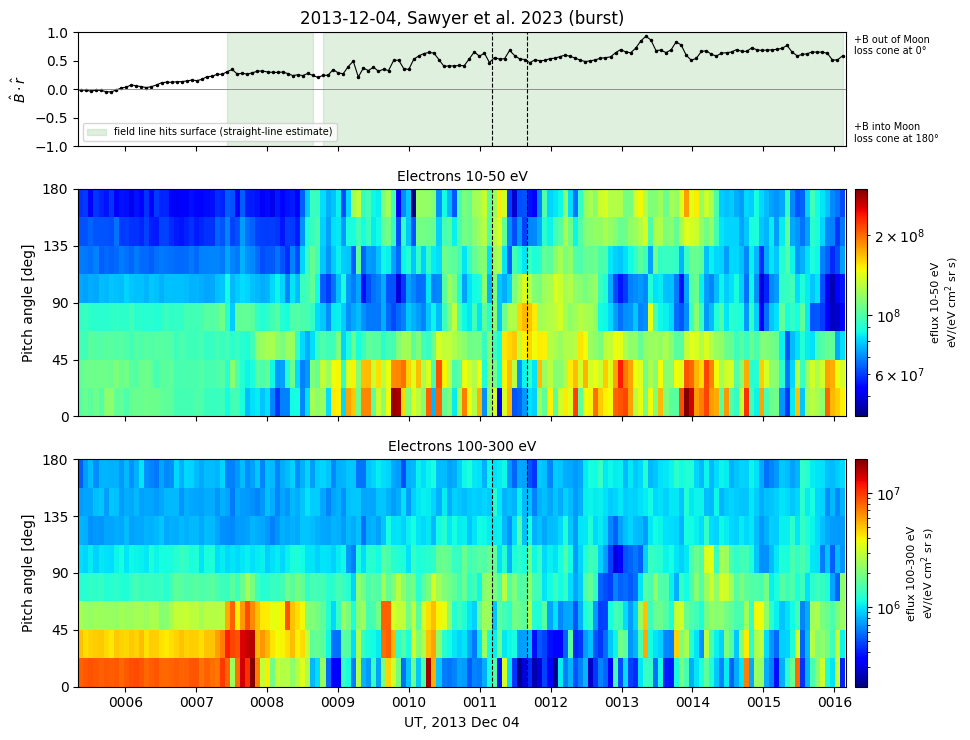

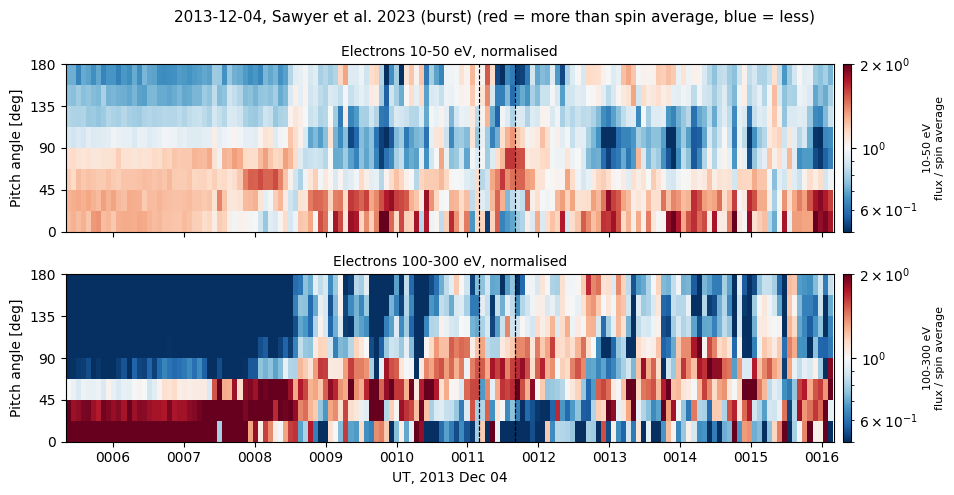

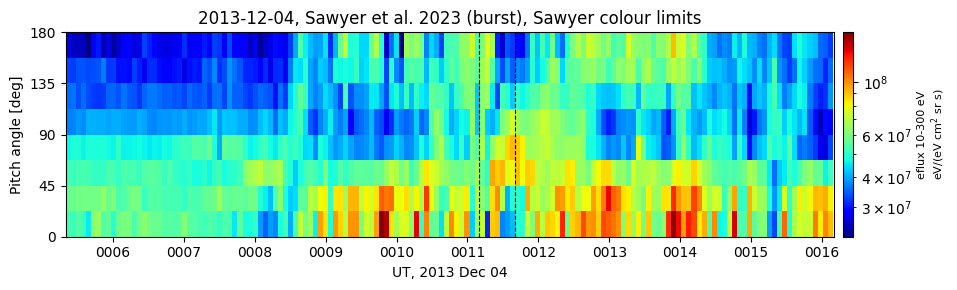

28-Nov-26 15:05:58: /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)

28-Nov-26 15:05:58: /usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2170: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)

28-Nov-26 15:06:08: /usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2197: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  return self._math_expression.parseString(toks[0][1:-1], parseAll=True)

28-Nov-26 15:06:08: /usr/local/lib/python3.13/dist-packages/pyparsing/util.py:466: PyparsingDeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)

28-Nov-26 1

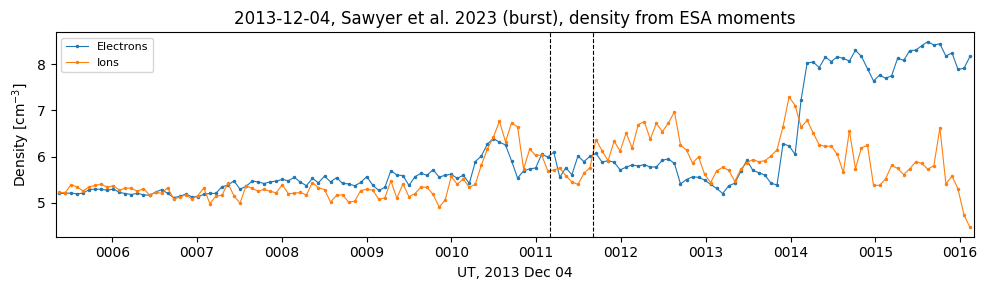

In [9]:
analyse_event(dict(trange=sawyer, marks=['2013-12-04 00:11:10', '2013-12-04 00:11:40'],
                   title='2013-12-04, Sawyer et al. 2023 (burst)', datatype='peeb'))


2013 04

28-Nov-26 15:06:09: /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)




2013 pass 4, lowest 33.1 km at 00:02 UT (full mode)


28-Nov-26 15:06:10: /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



peef: 145 spins in ['2013-01-14/23:57:00', '2013-01-15/00:07:00']


28-Nov-26 15:06:11: /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)

28-Nov-26 15:06:11: Rotation matrix sse_mat_cotrans has no input or output coordinates set
28-Nov-26 15:06:21: /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)

28-Nov-26 15:06:21: Rotation matrix sse_mat_cotrans has no input or output coordinates set
28-Nov-26 15:06:32: /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcno

  lowest altitude from state data: 32.6 km at 2013-01-15 00:02:20.566747189   (check against the csv)


28-Nov-26 15:06:42: /usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2197: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  return self._math_expression.parseString(toks[0][1:-1], parseAll=True)

28-Nov-26 15:06:42: /usr/local/lib/python3.13/dist-packages/pyparsing/util.py:466: PyparsingDeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)

28-Nov-26 15:06:42: /usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2178: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  ParserElement.resetCache()



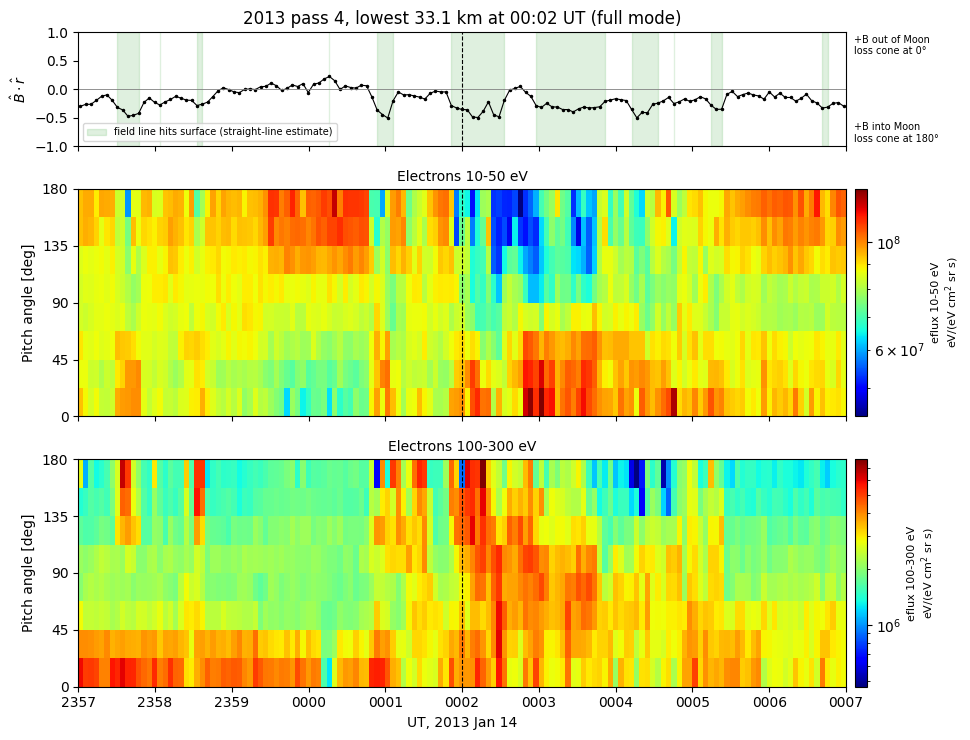

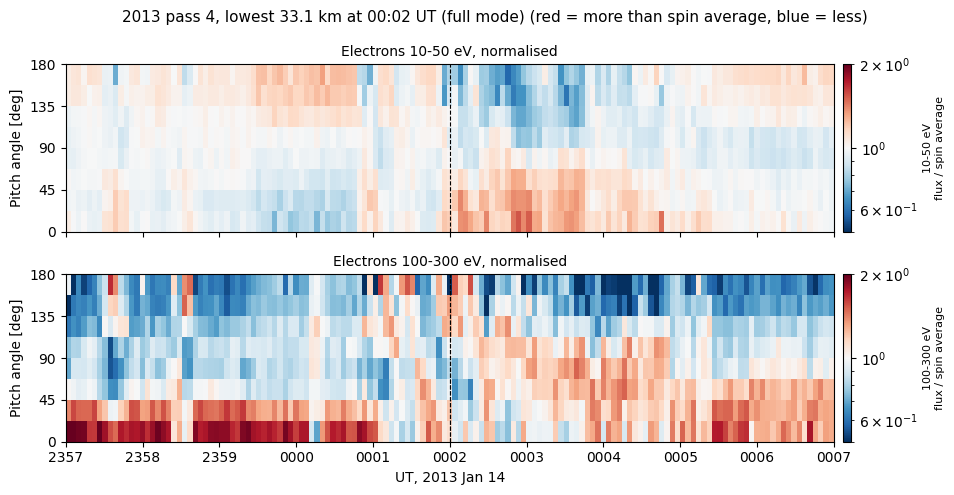

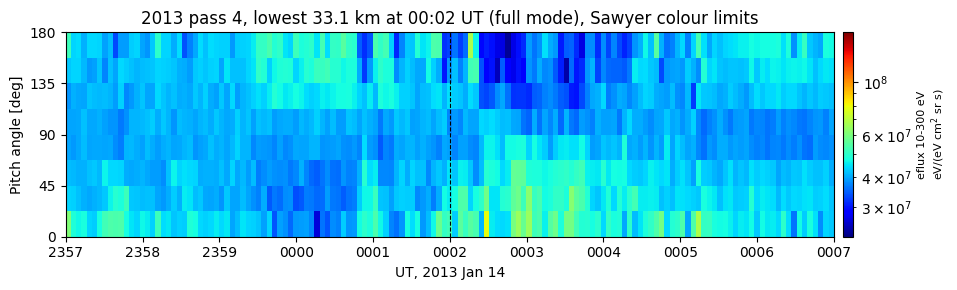

28-Nov-26 15:06:54: /usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2197: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  return self._math_expression.parseString(toks[0][1:-1], parseAll=True)

28-Nov-26 15:07:04: /usr/local/lib/python3.13/dist-packages/pyparsing/util.py:466: PyparsingDeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)

28-Nov-26 15:06:44: /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)

28-Nov-26 15:06:44: /usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2170: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)

28-Nov-26 1

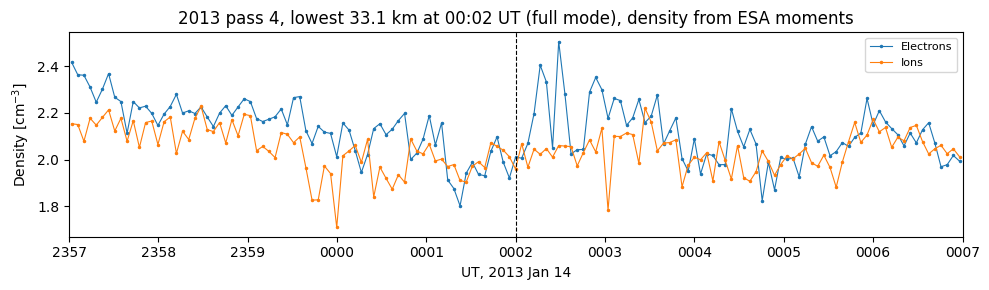

In [10]:
analyse_event(dict(trange=['2013-01-14/23:57:00', '2013-01-15/00:07:00'], marks=['2013-01-15 00:02:00'],
                   title='2013 pass 4, lowest 33.1 km at 00:02 UT (full mode)', datatype='peef'))

2014 04

28-Nov-26 15:07:14: /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)




2014 pass 4, lowest 44 km at 20:35 UT (full mode)


28-Nov-26 15:07:15: /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



peef: 127 spins in ['2014-05-26/20:31:00', '2014-05-26/20:40:00']


28-Nov-26 15:07:16: /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)

28-Nov-26 15:07:16: Rotation matrix sse_mat_cotrans has no input or output coordinates set
28-Nov-26 15:07:26: /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)

28-Nov-26 15:07:26: Rotation matrix sse_mat_cotrans has no input or output coordinates set
28-Nov-26 15:07:36: /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcno

  lowest altitude from state data: 43.5 km at 2014-05-26 20:35:17.489007711   (check against the csv)


28-Nov-26 15:07:46: /usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2197: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  return self._math_expression.parseString(toks[0][1:-1], parseAll=True)

28-Nov-26 15:07:46: /usr/local/lib/python3.13/dist-packages/pyparsing/util.py:466: PyparsingDeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)

28-Nov-26 15:07:46: /usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2178: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  ParserElement.resetCache()



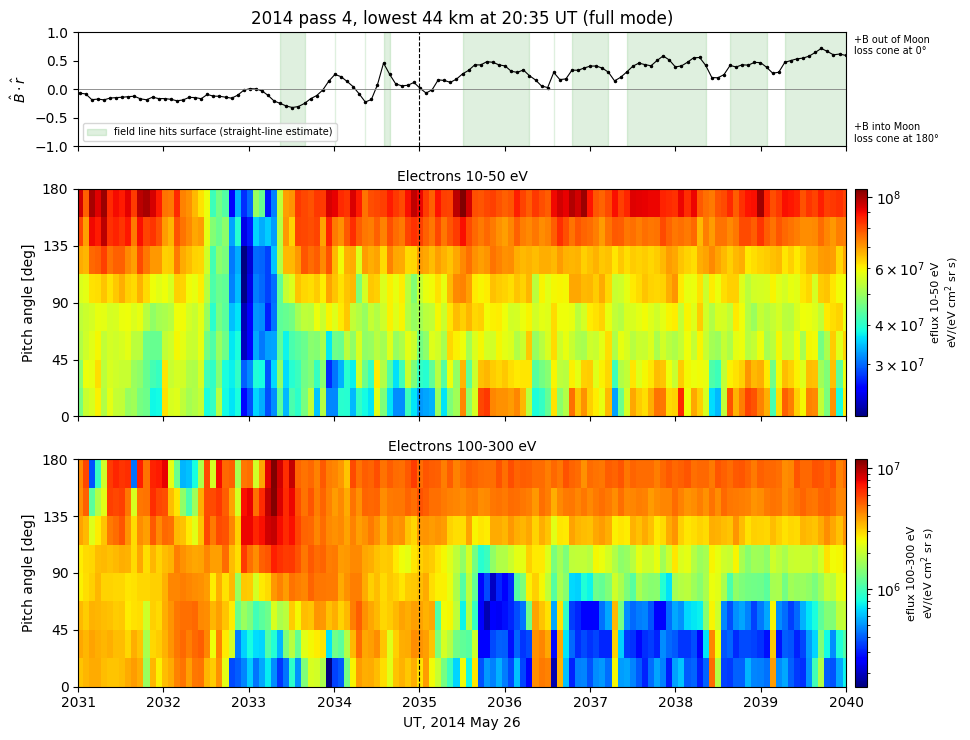

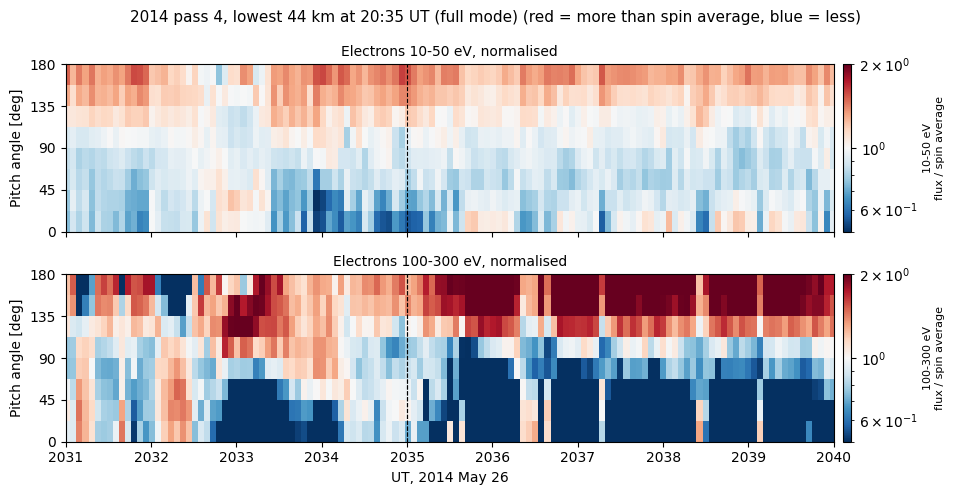

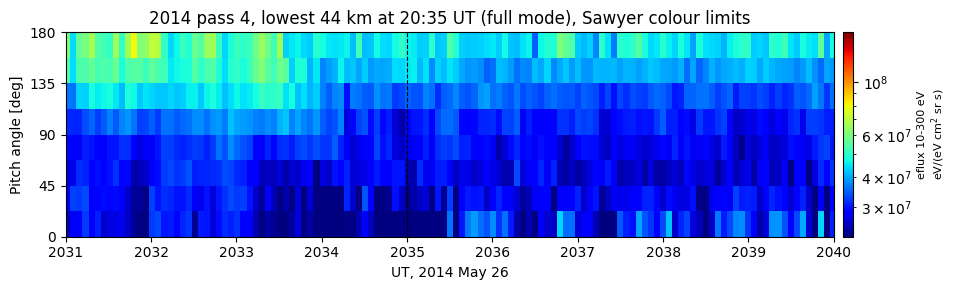

28-Nov-26 15:07:48: /usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)

28-Nov-26 15:07:48: /usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2170: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)

28-Nov-26 15:07:58: /usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2197: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  return self._math_expression.parseString(toks[0][1:-1], parseAll=True)

28-Nov-26 15:07:58: /usr/local/lib/python3.13/dist-packages/pyparsing/util.py:466: PyparsingDeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)

28-Nov-26 1

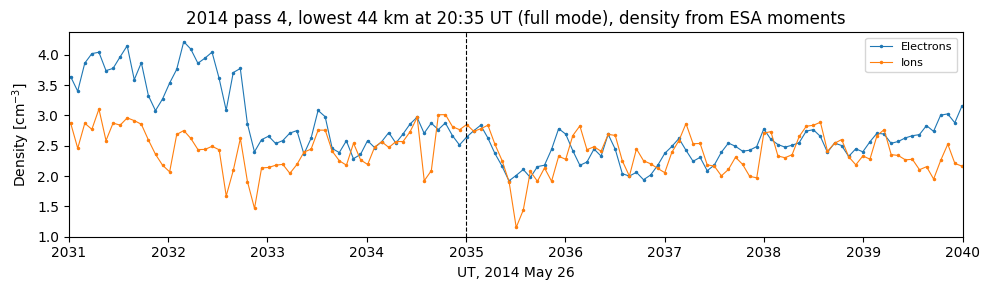

In [11]:
analyse_event(dict(trange=['2014-05-26/20:31:00', '2014-05-26/20:40:00'], marks=['2014-05-26 20:35:00'],
                   title='2014 pass 4, lowest 44 km at 20:35 UT (full mode)', datatype='peef'))